Import Required Libraries

In [32]:
import os
import re
import random
from collections import Counter, defaultdict

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


TensorFlow: 2.21.0
GPU available: True


Download the UR Fall Detection Dataset

In [22]:
import kagglehub

path = kagglehub.dataset_download(
    "shahliza27/ur-fall-detection-dataset"
)

print("Path to dataset files:", path)

100%|██████████| 4.18G/4.18G [04:00<00:00, 18.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1


Set dataset path and inspect files

In [33]:
DATASET_PATH = path

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Dataset path:", DATASET_PATH)
print("Top-level contents:", os.listdir(DATASET_PATH)[:20])


Dataset exists: True
Dataset path: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1
Top-level contents: ['UR_fall_detection_dataset_cam0_rgb']


Find the RGB frame folders

In [34]:
# Locate the RGB dataset folder even if its exact parent path varies.
DATA_ROOT = None

for root, dirs, files in os.walk(DATASET_PATH):
    for dirname in dirs:
        if dirname.lower() == "ur_fall_detection_dataset_cam0_rgb":
            DATA_ROOT = os.path.join(root, dirname)
            break
    if DATA_ROOT is not None:
        break

if DATA_ROOT is None:
    # Fallback: use the downloaded directory and search below it.
    DATA_ROOT = DATASET_PATH

print("RGB data root:", DATA_ROOT)

png_count = 0
for root, dirs, files in os.walk(DATA_ROOT):
    png_count += sum(f.lower().endswith(".png") for f in files)

print("PNG frames found:", png_count)


RGB data root: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb
PNG frames found: 11936


Group frames into labeled sequences

In [35]:
# Each sequence is represented by its own folder, e.g. adl-16-cam0-rgb.
sequence_frames = defaultdict(list)
unrecognized_folders = set()

for root, dirs, files in os.walk(DATA_ROOT):
    png_files = [f for f in files if f.lower().endswith(".png")]
    if not png_files:
        continue

    folder_name = os.path.basename(root)
    lower_name = folder_name.lower()

    if lower_name.startswith("adl-") or lower_name.startswith("adl_"):
        label = 0  # non-fall / ADL
    elif lower_name.startswith("fall-") or lower_name.startswith("fall_"):
        label = 1  # fall
    else:
        unrecognized_folders.add(folder_name)
        continue

    for filename in png_files:
        match = re.search(r"-(\d+)\.png$", filename, re.IGNORECASE)
        frame_number = int(match.group(1)) if match else 0
        sequence_frames[(root, folder_name, label)].append(
            (frame_number, os.path.join(root, filename))
        )

for key in sequence_frames:
    sequence_frames[key].sort(key=lambda item: item[0])

print("Sequences identified:", len(sequence_frames))
print("ADL sequences:", sum(k[2] == 0 for k in sequence_frames))
print("Fall sequences:", sum(k[2] == 1 for k in sequence_frames))
print("Total frames in identified sequences:",
      sum(len(v) for v in sequence_frames.values()))

print("\nFirst 12 sequences:")
for (folder, name, label), frames in list(sequence_frames.items())[:12]:
    print(name, "| label:", label, "| frames:", len(frames))

if not sequence_frames:
    print("\nNo sequence folders were recognized.")
    print("Inspect folder names under DATA_ROOT:", os.listdir(DATA_ROOT)[:30])
    raise ValueError("Could not identify ADL/fall sequence folders.")


Sequences identified: 70
ADL sequences: 40
Fall sequences: 30
Total frames in identified sequences: 11936

First 12 sequences:
adl-16-cam0-rgb | label: 0 | frames: 240
fall-06-cam0-rgb | label: 1 | frames: 100
adl-18-cam0-rgb | label: 0 | frames: 265
adl-06-cam0-rgb | label: 0 | frames: 230
adl-12-cam0-rgb | label: 0 | frames: 250
adl-04-cam0-rgb | label: 0 | frames: 150
fall-13-cam0-rgb | label: 1 | frames: 85
fall-28-cam0-rgb | label: 1 | frames: 66
adl-23-cam0-rgb | label: 0 | frames: 220
fall-25-cam0-rgb | label: 1 | frames: 85
adl-29-cam0-rgb | label: 0 | frames: 125
fall-08-cam0-rgb | label: 1 | frames: 91


Visualize normal and fall frames

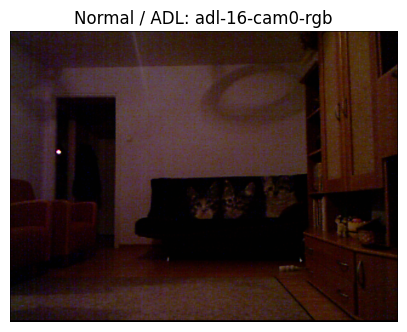

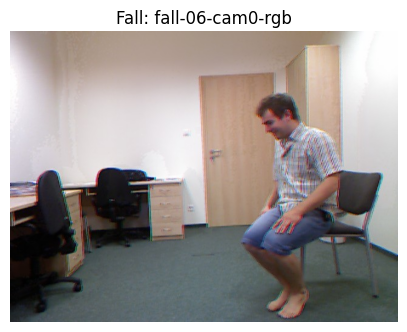

In [36]:
def show_sequence_sample(label_value, title, frame_position=0):
    candidates = [
        (key, frames) for key, frames in sequence_frames.items()
        if key[2] == label_value and len(frames) > 0
    ]
    if not candidates:
        print("No sequence found for:", title)
        return

    (folder, name, label), frames = candidates[0]
    frame_path = frames[min(frame_position, len(frames) - 1)][1]
    image = cv2.imread(frame_path)

    if image is None:
        print("Could not read image:", frame_path)
        return

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(5, 4))
    plt.imshow(image)
    plt.title(f"{title}: {name}")
    plt.axis("off")
    plt.show()

show_sequence_sample(0, "Normal / ADL")
show_sequence_sample(1, "Fall")


Preprocess each sequence into 16-frame tensors

In [37]:
NUM_FRAMES = 16
IMG_HEIGHT = 112
IMG_WIDTH = 112

def preprocess_sequence(frame_items, augment_jitter=False):
    if len(frame_items) == 0:
        return None

    paths = [item[1] for item in frame_items]
    total = len(paths)

    # Evenly sample frames. Small random temporal shift can be used for training augmentation.
    if total >= NUM_FRAMES:
        indices = np.linspace(0, total - 1, NUM_FRAMES).astype(int)
        if augment_jitter and total > NUM_FRAMES:
            shift = random.randint(0, max(0, total // 20))
            indices = np.clip(indices + shift, 0, total - 1)
            indices = np.sort(indices)
    else:
        # Repeat available frames if a sequence is shorter than NUM_FRAMES.
        indices = np.linspace(0, total - 1, NUM_FRAMES).astype(int)

    frames = []
    for idx in indices:
        image = cv2.imread(paths[int(idx)])
        if image is None:
            return None

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMG_WIDTH, IMG_HEIGHT))
        image = image.astype(np.float32) / 255.0
        frames.append(image)

    return np.stack(frames, axis=0)

print("Preprocessing function ready.")
print("Expected shape per sequence:",
      (NUM_FRAMES, IMG_HEIGHT, IMG_WIDTH, 3))


Preprocessing function ready.
Expected shape per sequence: (16, 112, 112, 3)


Build the dataset tensors and skip unreadable frames

In [38]:
X_list, y_list, sequence_names = [], [], []
failed_sequences = []

for key, frame_items in sequence_frames.items():
    folder, name, label = key
    tensor = preprocess_sequence(frame_items)

    if tensor is None:
        failed_sequences.append(name)
        continue

    X_list.append(tensor)
    y_list.append(label)
    sequence_names.append(name)

X = np.asarray(X_list, dtype=np.float32)
y = np.asarray(y_list, dtype=np.int32)

print("Successfully processed sequences:", len(X))
print("Skipped unreadable sequences:", len(failed_sequences))
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class counts [ADL, Fall]:",
      np.bincount(y, minlength=2) if len(y) else [])

if len(X) == 0:
    raise ValueError("No sequences were processed. Check the folder names and PNG files.")
if len(np.unique(y)) < 2:
    raise ValueError("Both ADL and fall classes are required. Check the detected labels.")


Successfully processed sequences: 70
Skipped unreadable sequences: 0
X shape: (70, 16, 112, 112, 3)
y shape: (70,)
Class counts [ADL, Fall]: [40 30]


Split into training, validation, and test sets

In [39]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training:", X_train.shape, "Class counts:", np.bincount(y_train, minlength=2))
print("Validation:", X_val.shape, "Class counts:", np.bincount(y_val, minlength=2))
print("Testing:", X_test.shape, "Class counts:", np.bincount(y_test, minlength=2))


Training: (49, 16, 112, 112, 3) Class counts: [28 21]
Validation: (10, 16, 112, 112, 3) Class counts: [6 4]
Testing: (11, 16, 112, 112, 3) Class counts: [6 5]


Apply training augmentation and calculate class weights

In [40]:
def augment_video(video):
    augmented = video.copy()

    if random.random() < 0.5:
        augmented = augmented[:, :, ::-1, :].copy()

    angle = random.uniform(-7, 7)
    center = (IMG_WIDTH // 2, IMG_HEIGHT // 2)
    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)

    rotated = []
    for frame in augmented:
        out = cv2.warpAffine(
            frame, matrix, (IMG_WIDTH, IMG_HEIGHT),
            borderMode=cv2.BORDER_REFLECT
        )
        rotated.append(out)

    return np.clip(np.stack(rotated), 0.0, 1.0).astype(np.float32)

# Add one augmented copy of each training sequence.
X_aug = np.stack([augment_video(v) for v in X_train])
X_train_final = np.concatenate([X_train, X_aug], axis=0)
y_train_final = np.concatenate([y_train, y_train], axis=0)

classes = np.unique(y_train_final)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_final
)
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}

print("Original training samples:", len(X_train))
print("Training samples after augmentation:", len(X_train_final))
print("Class weights:", class_weights)


Original training samples: 49
Training samples after augmentation: 98
Class weights: {0: 0.875, 1: 1.1666666666666667}


Build the 3D CNN model

In [41]:
model = models.Sequential([
    layers.Input(shape=(NUM_FRAMES, IMG_HEIGHT, IMG_WIDTH, 3)),

    layers.Conv3D(16, kernel_size=(3, 3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling3D(pool_size=(1, 2, 2)),

    layers.Conv3D(32, kernel_size=(3, 3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling3D(pool_size=(2, 2, 2)),

    layers.Conv3D(64, kernel_size=(3, 3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling3D(pool_size=(2, 2, 2)),

    layers.GlobalAveragePooling3D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,753 (292.00 KB)

 Trainable params: 74,753 (292.00 KB)

 Non-trainable params: 0 (0.00 B)

Train the model

In [42]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_final, y_train_final,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=2,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

print("Training finished.")


Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.5510 - loss: 0.6910 - val_accuracy: 0.6000 - val_loss: 0.6676
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.6224 - loss: 0.6278 - val_accuracy: 0.7000 - val_loss: 0.5536
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7347 - loss: 0.5457 - val_accuracy: 0.6000 - val_loss: 0.5533
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7449 - loss: 0.5185 - val_accuracy: 0.6000 - val_loss: 0.5651
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7551 - loss: 0.4784 - val_accuracy: 0.7000 - val_loss: 0.4547
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7041 - loss: 0.5141 - val_accuracy: 0.8000 - val_loss: 0.5197
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7551 - loss: 0.4384 - val_accuracy: 0.6000 - val_loss: 0.5717
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7857 - loss: 0.4398 - val_accuracy: 0.6000 - 

 Plot training and validation curves

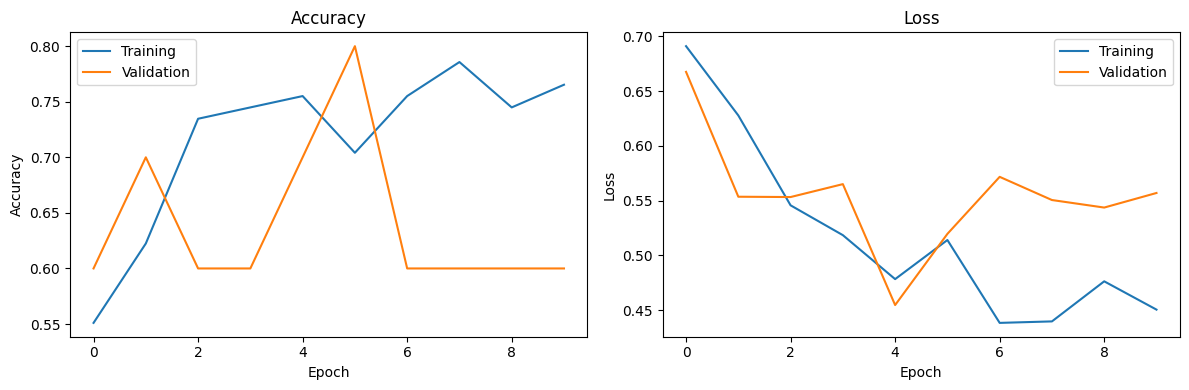

In [43]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


Evaluate: accuracy, precision, recall, F1, AUROC

In [44]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred, zero_division=0))

if len(np.unique(y_test)) == 2:
    print("AUROC    :", roc_auc_score(y_test, y_prob))
else:
    print("AUROC cannot be calculated because the test set has only one class.")

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Non-fall / ADL", "Fall"],
    zero_division=0
))


Accuracy : 0.9090909090909091
Precision: 0.8333333333333334
Recall   : 1.0
F1-score : 0.9090909090909091
AUROC    : 1.0

Classification report:
                precision    recall  f1-score   support

Non-fall / ADL       1.00      0.83      0.91         6
          Fall       0.83      1.00      0.91         5

      accuracy                           0.91        11
     macro avg       0.92      0.92      0.91        11
  weighted avg       0.92      0.91      0.91        11



Confusion matrix, ROC curve, and save model

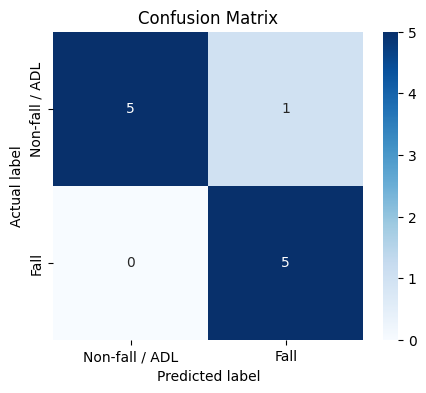

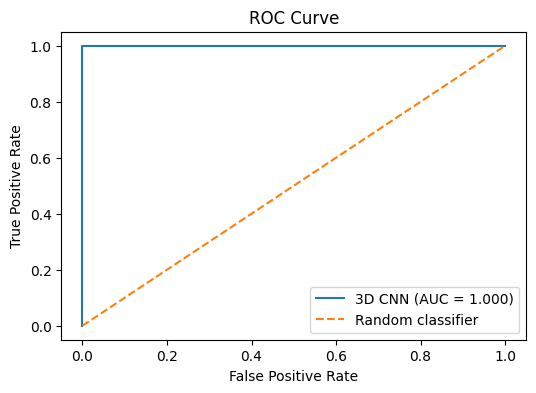

Model saved to /content/urfd_3d_cnn.keras
Misclassified test sequences: 1
Test sample 8: actual=Non-fall / ADL, predicted=Fall, fall_probability=0.526


In [45]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Non-fall / ADL", "Fall"],
    yticklabels=["Non-fall / ADL", "Fall"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix")
plt.show()

if len(np.unique(y_test)) == 2:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.figure(figsize=(6, 4))
    plt.plot(fpr, tpr, label=f"3D CNN (AUC = {roc_auc_score(y_test, y_prob):.3f})")
    plt.plot([0, 1], [0, 1], "--", label="Random classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()

model.save("/content/urfd_3d_cnn.keras")
print("Model saved to /content/urfd_3d_cnn.keras")

misclassified = np.where(y_pred != y_test)[0]
print("Misclassified test sequences:", len(misclassified))
for idx in misclassified:
    actual = "Fall" if y_test[idx] == 1 else "Non-fall / ADL"
    predicted = "Fall" if y_pred[idx] == 1 else "Non-fall / ADL"
    print(f"Test sample {idx}: actual={actual}, predicted={predicted}, fall_probability={y_prob[idx]:.3f}")


Conclusion
A baseline 3D CNN was implemented for fall versus non-fall classification using the RGB frame sequences available in the downloaded URFD dataset. Each sequence was sampled into 16 frames, resized to 112 × 112, normalized, and converted into a spatiotemporal tensor. The model was evaluated using accuracy, precision, recall, F1-score, AUROC, a confusion matrix, and an ROC curve. Misclassifications can be related to camera viewpoint, occlusion, motion blur, and similarities between falls and daily activities. Since this dataset version contains RGB PNG frames, depth and accelerometer data were not used. Results should be interpreted cautiously because the number of sequences is small and this is not a clinically validated system.